In [1]:
import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import structural_material_analysis as sma
from openmc_model import reactor_model, available_materials

/home/davide/anaconda3/envs/openmc0.15/lib/python3.12/site-packages/openmc/material.py:1596: UserWarning: Warning: sum of fractions do not add to 1, void fraction set to 0.09999999999999987
  warnings.warn(msg)


## Geometry

Please enter the name of the material!

In [2]:
material_name = "inconel718"

In [3]:
str_material = available_materials[material_name]
model, root = reactor_model(str_material)
geometry = model.geometry

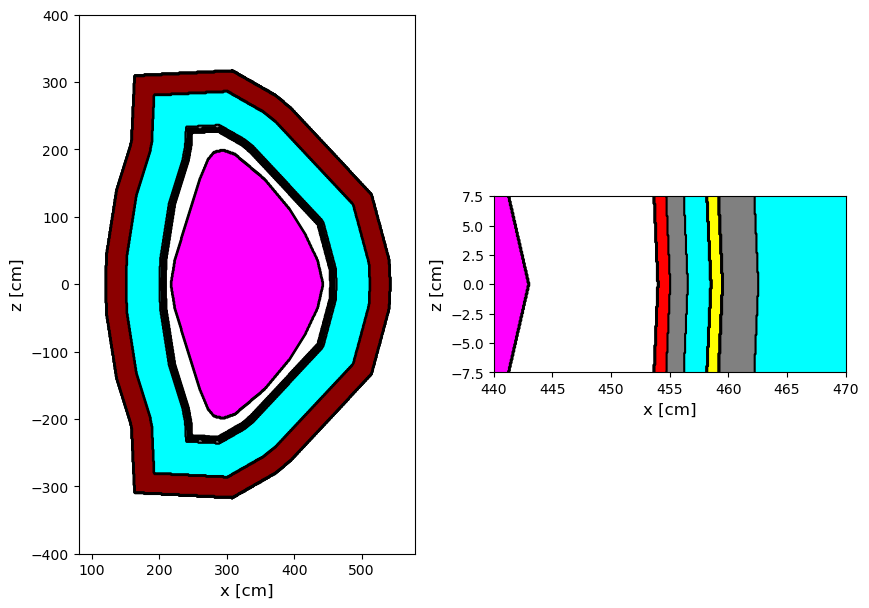

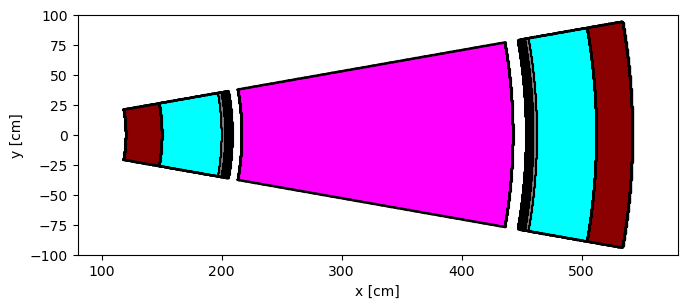

In [4]:
colors={root[0]:'magenta', root[1]:'white', root[2]:'red', root[3]:'grey', root[4]:'aqua', 
        root[5]:'yellow', root[6]:'grey', root[7]:'aqua', root[8]:'darkred', root[9]:'white'}

label_style = {
    'fontsize': 12,
    'fontweight': 'normal', #bold
    # 'family': 'Serif',
    'style': 'normal' #italic
}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10,7))
geometry.plot(origin=(330, 0, 0), basis='xz', width=[500, 800], pixels=[600, 600], axes=ax1, 
              color_by='cell', colors=colors, outline=True)
ax1.set_xlabel('x [cm]', **label_style)
ax1.set_ylabel('z [cm]', **label_style)
geometry.plot(origin=(455, 0, 0), basis='xz', width=[30, 15], pixels=[400, 400], axes=ax2, 
              color_by='cell', colors=colors, outline=True)
ax2.set_xlabel('x [cm]', **label_style)
ax2.set_ylabel('z [cm]', **label_style)
plt.show()

geometry.plot(origin=(330, 0, 0), basis='xy', width=[500, 200], pixels=[600, 600], 
              color_by='cell', colors=colors, outline=True)
plt.show()

## Results
- TBR
- Neutron spectra
- Heating
- NRT-DPA

In [5]:
fusion_power = 525e6  # units Watts
energy_per_fusion_reaction = 17.6e6  # units eV
eV_to_Joules = 1.60218e-19  # multiplication factor to convert eV to Joules
number_of_neutrons_per_second = fusion_power / (energy_per_fusion_reaction * eV_to_Joules)
print('Number of neutrons per second', number_of_neutrons_per_second, '\n')

fw_volume = 2234489.71 # units cm^3
fw_surface = 4468977.87 # units cm^2
vessel_inner_volume = 3376578.27 # units cm^3
vessel_inner_surface =  4502100.88 # units cm^2

Number of neutrons per second 1.8618098749544654e+20 



In [6]:
sp = openmc.StatePoint(f"results/{material_name}.h5")

In [7]:
tbr_total = sma.analysis.extract_tbr_contributions(sp, "TBR")
tbr_cc = sma.analysis.extract_tbr_contributions(sp, "TBR channel")
tbr_blanket = sma.analysis.extract_tbr_contributions(sp, "TBR blanket")

df = pd.DataFrame([tbr_total, tbr_cc, tbr_blanket], index=["Total", "Channel", "Blanket"])
print(df)

              TBR  TBR std. dev.       Li6       Li7
Total    1.107358       0.001262  1.100060  0.007298
Channel  0.286718       0.000544  0.285128  0.001590
Blanket  0.820640       0.001082  0.814932  0.005708


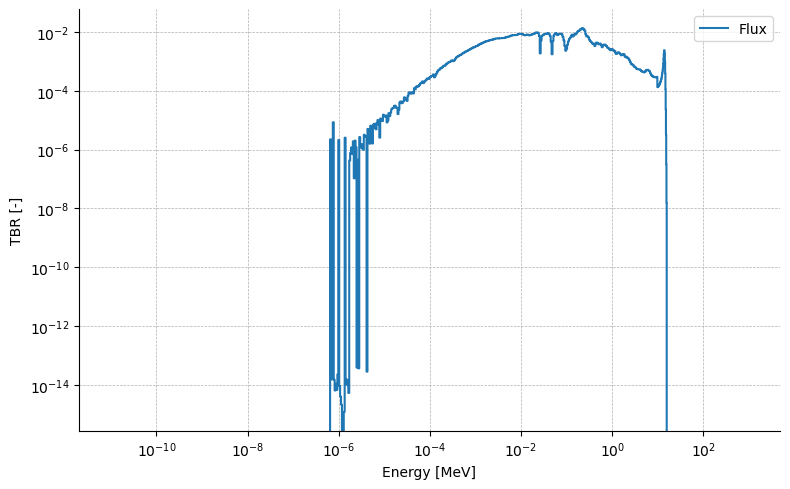

In [8]:
tbr_energy = sp.get_tally(name="TBR(energy)")
df_tbr_energy = tbr_energy.get_pandas_dataframe()
tbr_energy_val = df_tbr_energy['mean'].values

energy_bins = openmc.mgxs.GROUP_STRUCTURES["CCFE-709"]
energy_filter = openmc.EnergyFilter(energy_bins)

plt.figure(figsize=(8, 5))
plt.step(energy_filter.values[:-1] / 1e6, tbr_energy_val, where='mid', label='Flux')
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy [MeV]")
plt.ylabel('TBR [-]')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

In [9]:
sum(tbr_energy_val)

1.1144510559794785

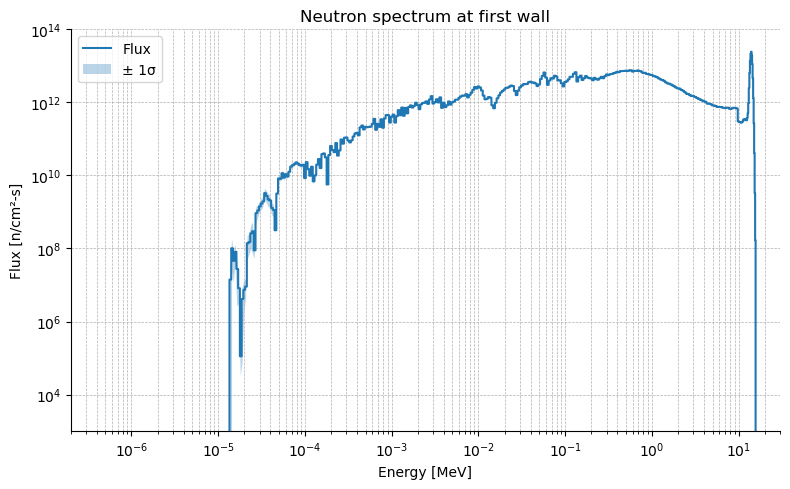

Mean neutron flux: 7.04e+14 ± 6.77e+12 n/cm²-s


In [10]:
tally = sp.get_tally(name="neutron_spectra_fw")

sma.analysis.plot_neutron_spectrum(tally, fw_volume, number_of_neutrons_per_second)

   Particle  Power [MW]  Power Density [MW/m³]
0   Neutron    2.601715               1.164344
1  Electron   47.645142              21.322605
2  Positron    0.484831               0.216976
3    Photon    3.311424               1.481960
4     Total   54.043111              24.185885


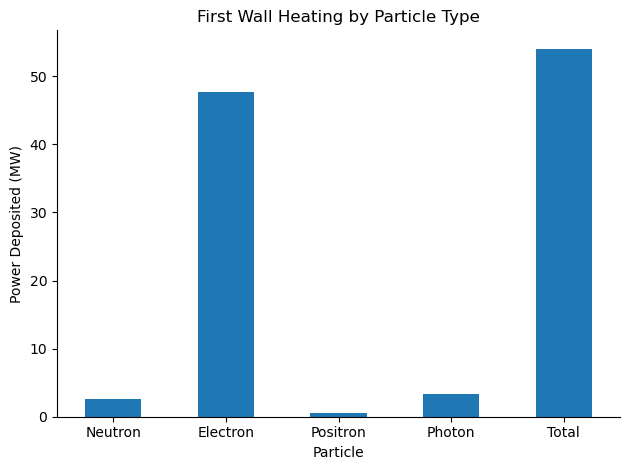

In [11]:
df = sma.analysis.compute_fw_heating(sp, number_of_neutrons_per_second, fw_volume)
print(df)

df.plot(kind='bar', y='Power [MW]', x='Particle', legend=False)
plt.ylabel('Power Deposited (MW)')
plt.title('First Wall Heating by Particle Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

In [13]:
E_source = 14.1  
tally = sp.get_tally(name='heating_fw')
number_of_neutrons_per_second * tally.mean.sum() / 1e6 / E_source

2.392268519506844e+19

The **damage-energy** ($T_{d}$) represents the kinetic energy available for creating atomic displacements. This variable can be used to compute the total number of displacements per atom (DPA). 

The current international standard [^1] for quantifying DPA is based on the **Kinchin-Pease model** or **NRT equation** [^2], which states that the number of Frenkel pairs produced ($N_{d}$) in a material with displacement energy $E_{d}$ for a nuclear deposited energy $T_{d}$ is:

$$
N_{d} = \dfrac{0.8T_{d}}{2E_d}
$$

where the factor 0.8 was introduced by the authors to allow for realistic atomic scattering instead of the hard core approximation.

[^1]: ASTM Standard E693-94, *Standard practice for characterising neutron exposure in iron and low alloy steels in terms of displacements per atom (DPA)*, 1994  
[^2]: [NRT paper](https://doi.org/10.1016%2F0029-5493%2875%2990035-7)


In [ ]:
dpa_tally_fw = sp.get_tally(name="dpa_fw")
df_fw = dpa_tally_fw.get_pandas_dataframe()

props = sma.materials.properties.firstwall[material_name]

result = sma.analysis.compute_dpa_from_tally(
    df=df_fw,
    number_of_neutrons_per_second=number_of_neutrons_per_second,  
    atomic_mass_u=props["mass_u"],                
    density_g_per_cm3=fw_material.density,  
    volume_cm3=fw_volume,
    Ed_eV=props["Ed"],  
)
print(f"DPA = {result['DPA']}")